Comparing basic policies with priority-based policy.

In [43]:
import os
import sys
import importlib

project_root = os.path.abspath(os.path.join(os.getcwd(), ".."))
if project_root not in sys.path:
    sys.path.insert(0, project_root)

for mod in ["src.constants", "src.simulation", "src.policies", "src.mdp"]:
    if mod in sys.modules:
        importlib.reload(sys.modules[mod])

import numpy as np
import matplotlib.pyplot as plt
from src.constants import (
    N_ASSETS, HORIZON, GAMMA, ANNUAL_BUDGET, FAILURE_PENALTY, N_STATES,
    ACTIONS, ACTION_COST, INITIAL_DIST, P)
from src.simulation import (simulate_network, run_mc, total_discounted_cost)
from src.policies import policy_do_nothing, policy_worst_first, policy_threshold
from src.mdp import solve_unconstrained_mdp, compute_priority_table, make_index_policy

In [32]:
V, pi = solve_unconstrained_mdp(P, ACTION_COST, FAILURE_PENALTY, ACTIONS, HORIZON, GAMMA)



pri = compute_priority_table(V, 0, P, ACTION_COST, FAILURE_PENALTY, ACTIONS, GAMMA)
print("\nPriority (rows = state, cols = action):")
print(f"{'':>10} {'minor':>10} {'major':>10}")
for s in range(N_STATES):
    print(f"  state {s}: {pri[s, 1]:>10.3f} {pri[s, 2]:>10.3f}")


Priority (rows = state, cols = action):
                minor      major
  state 0:     -0.616     -0.928
  state 1:     -0.110     -0.772
  state 2:      0.450     -0.515
  state 3:      2.904      0.001
  state 4:      1.249      0.539


In [38]:
index_pol = make_index_policy(V, P, ACTION_COST, FAILURE_PENALTY, ACTIONS, GAMMA)
crit_idx, cost_idx = run_mc(index_pol, n_reps=20)

crit_th, cost_th = run_mc(policy_threshold(2), n_reps=20)
crit_wf, cost_wf = run_mc(policy_worst_first, n_reps=20)

print(f"Threshold (k={2}): {cost_th.mean():>8.0f} ± {cost_th.std():>5.0f}")
print(f"Index policy:         {cost_idx.mean():>8.0f} ± {cost_idx.std():>5.0f}")
print(f"Worst-first:          {cost_wf.mean():>8.0f} ± {cost_wf.std():>5.0f}")

Threshold (k=2):    16500 ±  1010
Index policy:            11568 ±   634
Worst-first:             20817 ±   939


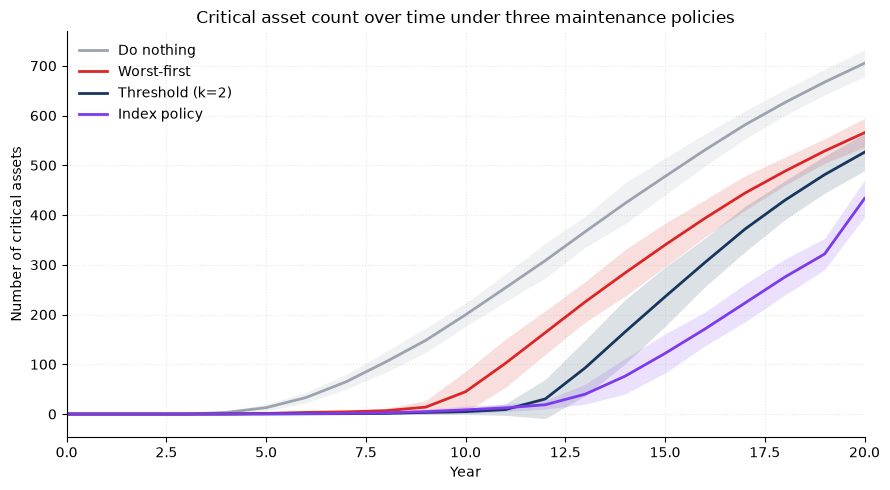

In [44]:
import numpy as np
import matplotlib.pyplot as plt

N_REPS = 20          
K_BEST = 2           

# Monte Carlo for each policy 
crit_dn, cost_dn = run_mc(policy_do_nothing,  n_reps=N_REPS)
crit_wf, cost_wf = run_mc(policy_worst_first, n_reps=N_REPS)
crit_th, cost_th = run_mc(policy_threshold(K_BEST), n_reps=N_REPS)
crit_idx, cost_idx = run_mc(index_pol, n_reps=20)

years = np.arange(crit_dn.shape[1])

def band(arr, z=1.96):
    mean = arr.mean(axis=0)
    sd   = arr.std(axis=0, ddof=1)
    return mean, mean - z*sd, mean + z*sd

# --- Plot ---
fig, ax = plt.subplots(figsize=(9, 5))

policies = [
    (crit_dn, "Do nothing",           "#9CA3AF"),
    (crit_wf, "Worst-first",          "#DC2626"),
    (crit_th, f"Threshold (k={K_BEST})", "#17365D"),
    (crit_idx, "Index policy",        "#7C3AED"),
]

for arr, label, color in policies:
    mean, lo, hi = band(arr)
    ax.plot(years, mean, label=label, color=color, linewidth=2)
    ax.fill_between(years, lo, hi, color=color, alpha=0.15, linewidth=0)

ax.set_xlabel("Year")
ax.set_ylabel("Number of critical assets")
ax.set_title("Critical asset count over time under three maintenance policies")
ax.legend(frameon=False, loc="upper left")
ax.grid(alpha=0.3, linestyle=":")
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.set_xlim(0, years[-1])

plt.tight_layout()
plt.savefig("../figures/critical_comparison.png", dpi=150, bbox_inches="tight")
plt.show()

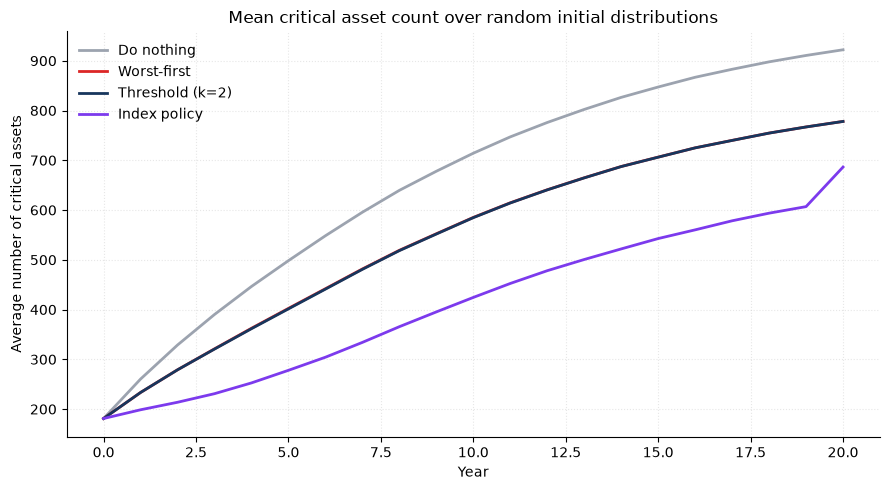

In [46]:
import numpy as np
import matplotlib.pyplot as plt

N_REPS = 20
K_BEST = 2

# Random initial distributions
rng = np.random.default_rng(42)
n_scenarios = 50
scenarios = rng.dirichlet(np.ones(5), size=n_scenarios)

# Evaluate each policy for each scenario
policy_results = {}

for policy_name, policy in [
    ("Do nothing", policy_do_nothing),
    ("Worst-first", policy_worst_first),
    ("Threshold (k=2)", lambda s, b, t=None: policy_threshold(2)(s, b, t)),
    ("Index policy", index_pol),
]:
    curves = []

    for dist in scenarios:
        crit, _ = run_mc(policy, n_reps=N_REPS, initial_dist=dist)
        curves.append(crit.mean(axis=0))   # average across Monte Carlo runs for this scenario

    policy_results[policy_name] = np.array(curves)  # shape: (n_scenarios, horizon+1)

# Now average across scenarios
years = np.arange(0, 21)

fig, ax = plt.subplots(figsize=(9, 5))

policies = [
    ("Do nothing", policy_results["Do nothing"], "#9CA3AF"),
    ("Worst-first", policy_results["Worst-first"], "#DC2626"),
    ("Threshold (k=2)", policy_results["Threshold (k=2)"], "#17365D"),
    ("Index policy", policy_results["Index policy"], "#7C3AED"),
]

for label, curves, color in policies:
    mean_curve = curves.mean(axis=0)
    ax.plot(years, mean_curve, label=label, color=color, linewidth=2)

ax.set_xlabel("Year")
ax.set_ylabel("Average number of critical assets")
ax.set_title("Mean critical asset count over random initial distributions")
ax.legend(frameon=False, loc="upper left")
ax.grid(alpha=0.3, linestyle=":")
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

plt.tight_layout()
plt.show()
